# **DSK807 Applied Machine Learning**
## **L12 Tutorial: Neural Network Regression with California Housing**

**Goal: **predict median house value using a neural network. Compare model architecture and learning rate. The target is measured in units of $100,000 and is capped in this dataset.



---


### **1. Load and inspect the data**
California Housing has 8 numerical input features and a continuous target.

In [1]:
from sklearn.datasets import fetch_california_housing
import pandas as pd
import torch

housing = fetch_california_housing()
X = housing.data
y = housing.target

print("Features:", housing.feature_names)
print("Data shape:", X.shape)
print("First five house values:", y[:5])

pd.DataFrame(X, columns=housing.feature_names).head()

Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Data shape: (20640, 8)
First five house values: [4.526 3.585 3.521 3.413 3.422]


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25




---


### **2. Split the data and scale the features**
We use a training set, validation set, and test set. Fit the scaler only on training data to avoid data leakage.

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.20, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Training: (13209, 8)
Validation: (3303, 8)
Test: (4128, 8)


In [3]:
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

def to_tensor(arr):
    return torch.tensor(arr, dtype=torch.float32, device=device)

X_train_t = to_tensor(X_train)
X_val_t = to_tensor(X_val)
X_test_t = to_tensor(X_test)

y_train_t = to_tensor(y_train).reshape(-1, 1)
y_val_t = to_tensor(y_val).reshape(-1, 1)
y_test_t = to_tensor(y_test).reshape(-1, 1)

print()
print(f"Device: {device}")
for name, t in [("X_train_t", X_train_t), ("X_val_t", X_val_t), ("X_test_t", X_test_t),
                ("y_train_t", y_train_t), ("y_val_t", y_val_t), ("y_test_t", y_test_t)]:
    print(f"{name:<10} shape={str(tuple(t.shape)):<12} dtype={t.dtype}  device={t.device}")


Device: mps
X_train_t  shape=(13209, 8)   dtype=torch.float32  device=mps:0
X_val_t    shape=(3303, 8)    dtype=torch.float32  device=mps:0
X_test_t   shape=(4128, 8)    dtype=torch.float32  device=mps:0
y_train_t  shape=(13209, 1)   dtype=torch.float32  device=mps:0
y_val_t    shape=(3303, 1)    dtype=torch.float32  device=mps:0
y_test_t   shape=(4128, 1)    dtype=torch.float32  device=mps:0




---


### **3. Build a baseline neural network**
The output layer has **one neuron and no activation function** because this is regression. We use MSE for training and MAE for monitoring.

In [4]:
import torch.nn as nn

torch.manual_seed(42)

model = nn.Sequential(
    nn.Linear(8, 256),
    nn.ReLU(),
    nn.Linear(256, 128),
    nn.ReLU(),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1),
).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
loss_fn = nn.MSELoss()   # training loss (Keras: loss="mse")
mae_fn = nn.L1Loss()     # metric only (Keras: metrics=["mae"])

print(model)
print(f"Model device: {next(model.parameters()).device}")
print()
print(f"{'Parameter':<12}{'Shape':<12}{'Count':>8}")
total = 0
for name, p in model.named_parameters():
    print(f"{name:<12}{str(tuple(p.shape)):<12}{p.numel():>8}")
    total += p.numel()
print(f"{'Total parameters':<24}{total:>8}")

# import tensorflow as tf
# from tensorflow import keras
# from tensorflow.keras import layers

# tf.keras.utils.set_random_seed(42)

# model = keras.Sequential()
# model.add(layers.Input(shape=(8,)))
# model.add(layers.Dense(64, activation="relu"))
# model.add(layers.Dense(32, activation="relu"))
# model.add(layers.Dense(1))

# model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
#               loss="mse", metrics=["mae"])
# model.summary()

Sequential(
  (0): Linear(in_features=8, out_features=256, bias=True)
  (1): ReLU()
  (2): Linear(in_features=256, out_features=128, bias=True)
  (3): ReLU()
  (4): Linear(in_features=128, out_features=64, bias=True)
  (5): ReLU()
  (6): Linear(in_features=64, out_features=32, bias=True)
  (7): ReLU()
  (8): Linear(in_features=32, out_features=1, bias=True)
)
Model device: mps:0

Parameter   Shape          Count
0.weight    (256, 8)        2048
0.bias      (256,)           256
2.weight    (128, 256)     32768
2.bias      (128,)           128
4.weight    (64, 128)       8192
4.bias      (64,)             64
6.weight    (32, 64)        2048
6.bias      (32,)             32
8.weight    (1, 32)           32
8.bias      (1,)               1
Total parameters           45569




---


### **4. Train and inspect the learning curves**
We use the validation set during training, not the test set.

In [5]:
import torch
from torch.utils.data import TensorDataset, DataLoader
from early_stopping_pytorch import EarlyStopping

train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=32, shuffle=True)

epochs = 100
history = {"loss": [], "mae": [], "val_loss": [], "val_mae": []}

early_stopping = EarlyStopping(patience=10, delta=0.001, verbose=True, path="checkpoint.pt")

for epoch in range(epochs):
    # --- Training ---
    model.train()
    total_loss, total_mae, n = 0.0, 0.0, 0
    for xb, yb in train_loader:
        pred = model(xb)
        loss = loss_fn(pred, yb)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(xb)
        total_mae += mae_fn(pred, yb).item() * len(xb)
        n += len(xb)

    # --- Validation ---
    model.eval()
    with torch.no_grad():
        val_pred = model(X_val_t)
        val_loss = loss_fn(val_pred, y_val_t).item()
        val_mae = mae_fn(val_pred, y_val_t).item()

    history["loss"].append(total_loss / n)
    history["mae"].append(total_mae / n)
    history["val_loss"].append(val_loss)
    history["val_mae"].append(val_mae)

    print(f"Epoch {epoch + 1}/{epochs} - "
          f"loss: {history['loss'][-1]:.4f} - mae: {history['mae'][-1]:.4f} - "
          f"val_loss: {val_loss:.4f} - val_mae: {val_mae:.4f}")

    # --- Early stopping check ---
    early_stopping(val_loss, model)
    if early_stopping.early_stop:
        print(f"Early stopping at epoch {epoch + 1}")
        break

# --- Restore the best weights ---
model.load_state_dict(torch.load("checkpoint.pt", map_location=device, weights_only=True))
print("Restored best weights from checkpoint.pt")

# # callback = keras.callbacks.EarlyStopping(monitor='val_loss', patience=3)

# history = model.fit(X_train, y_train,
#                     validation_data=(X_val, y_val),
#                     epochs=20, batch_size=32)


Epoch 1/100 - loss: 0.7253 - mae: 0.5771 - val_loss: 0.4098 - val_mae: 0.4513
Validation loss decreased (inf --> 0.409773).  Saving model ...
Epoch 2/100 - loss: 0.3783 - mae: 0.4350 - val_loss: 0.3948 - val_mae: 0.4571
Validation loss decreased (0.409773 --> 0.394770).  Saving model ...
Epoch 3/100 - loss: 0.3508 - mae: 0.4187 - val_loss: 0.4652 - val_mae: 0.4779
EarlyStopping counter: 1 out of 10
Epoch 4/100 - loss: 0.3434 - mae: 0.4091 - val_loss: 0.3660 - val_mae: 0.4257
Validation loss decreased (0.394770 --> 0.366038).  Saving model ...
Epoch 5/100 - loss: 0.3358 - mae: 0.4047 - val_loss: 0.3473 - val_mae: 0.4048
Validation loss decreased (0.366038 --> 0.347276).  Saving model ...
Epoch 6/100 - loss: 0.3210 - mae: 0.3950 - val_loss: 0.3820 - val_mae: 0.4059
EarlyStopping counter: 1 out of 10
Epoch 7/100 - loss: 0.3111 - mae: 0.3874 - val_loss: 0.3794 - val_mae: 0.3934
EarlyStopping counter: 2 out of 10
Epoch 8/100 - loss: 0.3073 - mae: 0.3863 - val_loss: 0.3212 - val_mae: 0.3939


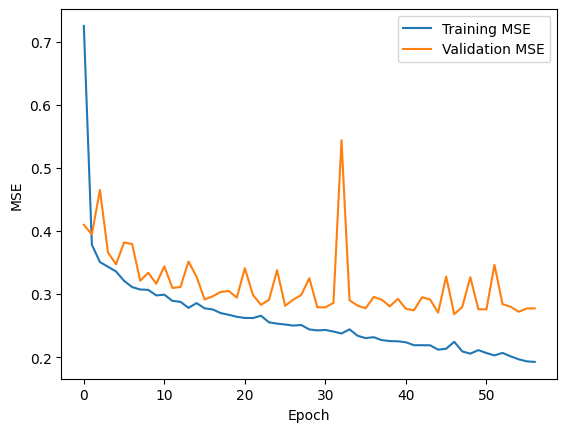

Final validation MAE: 0.346


In [6]:
# with early stop

import matplotlib.pyplot as plt
plt.plot(history["loss"], label="Training MSE")
plt.plot(history["val_loss"], label="Validation MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.legend()
plt.show()

print("Final validation MAE:", round(history["val_mae"][-1], 3))

In [ ]:
# 不深
# Final validation MAE: 0.389

# 身一點
# Final validation MAE: 0.411

# 4曾 
# Final validation MAE: 0.362

# 5 layer
# Final validation MAE: 0.346

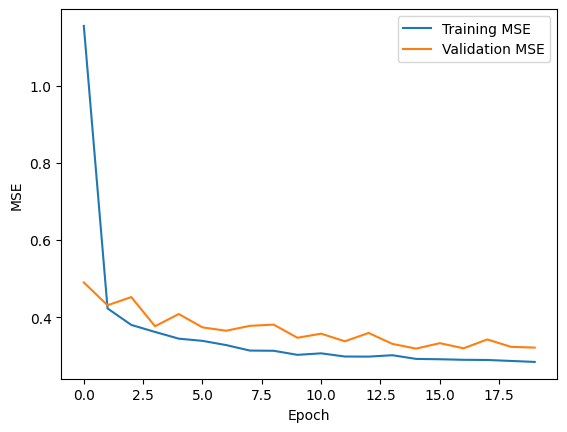

Final validation MAE: 0.394


In [ ]:
# # without early stop

# import matplotlib.pyplot as plt
# plt.plot(history["loss"], label="Training MSE")
# plt.plot(history["val_loss"], label="Validation MSE")
# plt.xlabel("Epoch")
# plt.ylabel("MSE")
# plt.legend()
# plt.show()

# print("Final validation MAE:", round(history["val_mae"][-1], 3))



---


### **5. Compare a smaller architecture**
Change only the architecture. Keep the optimizer, learning rate, batch size, and epochs unchanged. Compare validation MAE with the baseline.

In [10]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader


def train_model(model, epochs=20, batch_size=32, lr=0.001):
    """Equivalent of Keras compile() + fit(..., verbose=0). Returns a history dict."""
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    mae_fn = nn.L1Loss()
    loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=batch_size, shuffle=True)
    history = {"loss": [], "mae": [], "val_loss": [], "val_mae": []}

    for epoch in range(epochs):
        model.train()
        total_loss, total_mae, n = 0.0, 0.0, 0
        for xb, yb in loader:
            pred = model(xb)
            loss = loss_fn(pred, yb)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(xb)
            total_mae += mae_fn(pred, yb).item() * len(xb)
            n += len(xb)

        model.eval()
        with torch.no_grad():
            val_pred = model(X_val_t)
            history["val_loss"].append(loss_fn(val_pred, y_val_t).item())
            history["val_mae"].append(mae_fn(val_pred, y_val_t).item())
        history["loss"].append(total_loss / n)
        history["mae"].append(total_mae / n)

    return history


def count_params(model):
    return sum(p.numel() for p in model.parameters())


torch.manual_seed(42)

small_model = nn.Sequential(
    nn.Linear(8, 16),
    nn.ReLU(),
    nn.Linear(16, 1),
).to(device)

small_history = train_model(small_model, epochs=20, batch_size=32, lr=0.001)

print("Baseline validation MAE:", round(history["val_mae"][-1], 3))
print("Small model validation MAE:", round(small_history["val_mae"][-1], 3))
print("Baseline parameters:", count_params(model))
print("Small model parameters:", count_params(small_model))

# tf.keras.utils.set_random_seed(42)

# small_model = keras.Sequential()
# small_model.add(layers.Input(shape=(8,)))
# small_model.add(layers.Dense(16, activation="relu"))
# small_model.add(layers.Dense(1))

# small_model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
#                     loss="mse", metrics=["mae"])

# small_history = small_model.fit(X_train, y_train,
#                                 validation_data=(X_val, y_val),
#                                 epochs=20, batch_size=32, verbose=0)

# print("Baseline validation MAE:", round(history.history["val_mae"][-1], 3))
# print("Small model validation MAE:", round(small_history.history["val_mae"][-1], 3))
# print("Baseline parameters:", model.count_params())
# print("Small model parameters:", small_model.count_params())

Baseline validation MAE: 0.389
Small model validation MAE: 0.432
Baseline parameters: 2689
Small model parameters: 161


### 6. Change the learning rate
Return to the baseline architecture. Try a learning rate of 0.01 instead of 0.001. Is convergence faster, slower, or less stable?

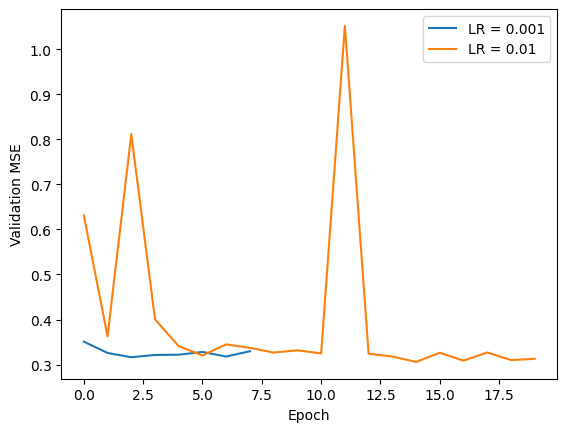

In [11]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader


def train_model(model, epochs=20, batch_size=32, lr=0.001):
    """Equivalent of Keras compile() + fit(..., verbose=0). Returns a history dict."""
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    mae_fn = nn.L1Loss()
    loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=batch_size, shuffle=True)
    history = {"loss": [], "mae": [], "val_loss": [], "val_mae": []}

    for epoch in range(epochs):
        model.train()
        total_loss, total_mae, n = 0.0, 0.0, 0
        for xb, yb in loader:
            pred = model(xb)
            loss = loss_fn(pred, yb)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(xb)
            total_mae += mae_fn(pred, yb).item() * len(xb)
            n += len(xb)

        model.eval()
        with torch.no_grad():
            val_pred = model(X_val_t)
            history["val_loss"].append(loss_fn(val_pred, y_val_t).item())
            history["val_mae"].append(mae_fn(val_pred, y_val_t).item())
        history["loss"].append(total_loss / n)
        history["mae"].append(total_mae / n)

    return history


torch.manual_seed(42)

fast_model = nn.Sequential(
    nn.Linear(8, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1),
).to(device)

fast_history = train_model(fast_model, epochs=20, batch_size=32, lr=0.01)

plt.plot(history["val_loss"], label="LR = 0.001")
plt.plot(fast_history["val_loss"], label="LR = 0.01")
plt.xlabel("Epoch")
plt.ylabel("Validation MSE")
plt.legend()
plt.show()

### **7. Evaluate the baseline on the held-out test set**
We use the test set only at the end. MAE and RMSE are in units of $100,000. R² is unitless.

In [7]:
import numpy as np
import torch
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

model.eval()
with torch.no_grad():
    predictions = model(X_test_t).cpu().numpy().flatten()

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("Test MAE:", round(mae, 3), "($100,000 units)")
print("Test RMSE:", round(rmse, 3), "($100,000 units)")
print("Test R2:", round(r2, 3))

# import numpy as np
# from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# predictions = model.predict(X_test, verbose=0).flatten()

# mae = mean_absolute_error(y_test, predictions)
# rmse = np.sqrt(mean_squared_error(y_test, predictions))
# r2 = r2_score(y_test, predictions)

# print("Test MAE:", round(mae, 3), "($100,000 units)")
# print("Test RMSE:", round(rmse, 3), "($100,000 units)")
# print("Test R2:", round(r2, 3))


Test MAE: 0.337 ($100,000 units)
Test RMSE: 0.509 ($100,000 units)
Test R2: 0.802


In [ ]:
# 三層 不廣
# Test MAE: 0.374 ($100,000 units)
# Test RMSE: 0.553 ($100,000 units)
# Test R2: 0.767

# 三層 更廣一點
# Test MAE: 0.384 ($100,000 units)
# Test RMSE: 0.564 ($100,000 units)
# Test R2: 0.757

# 4 層
# Test MAE: 0.359 ($100,000 units)
# Test RMSE: 0.524 ($100,000 units)
# Test R2: 0.79

# 5 layer
# Test MAE: 0.365 ($100,000 units)
# Test RMSE: 0.529 ($100,000 units)
# Test R2: 0.786

# 5 layer, 10 early stop 
# Test MAE: 0.337 ($100,000 units)
# Test RMSE: 0.509 ($100,000 units)
# Test R2: 0.802

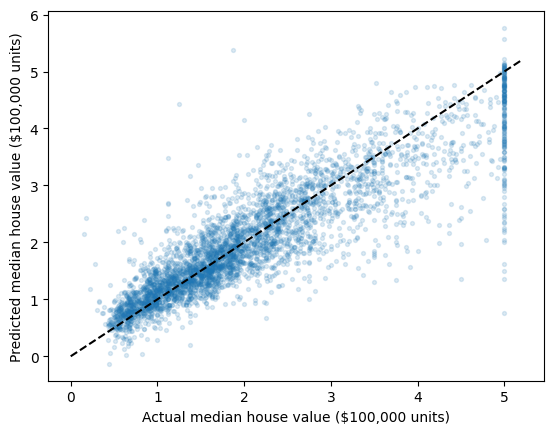

In [13]:
plt.scatter(y_test, predictions, alpha=0.15, s=8)
plt.plot([0, 5.2], [0, 5.2], "k--")
plt.xlabel("Actual median house value ($100,000 units)")
plt.ylabel("Predicted median house value ($100,000 units)")
plt.show()